# Customer Churn Prediction
## Notebook 1 — Exploratory Data Analysis

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 features)  
**Goal:** Understand patterns in customer behaviour that lead to churn before building a predictive model.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

df = pd.read_csv("C:/Users/polep/Downloads/Customer_churn/Customer_churn/data/Customer-Churn.csv")
print('Shape:', df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Basic Overview

In [4]:
print('Data types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nWhitespace entries in TotalCharges:', (df['TotalCharges'].str.strip() == '').sum())

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling 

## 2. Target Distribution — How Many Customers Churn?

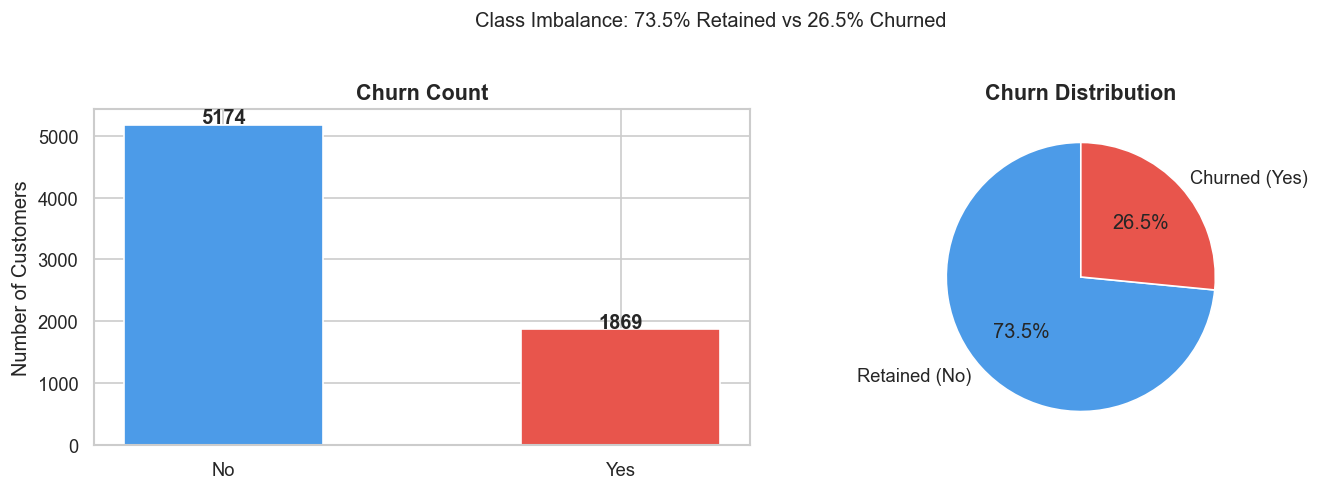

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(churn_counts.index, churn_counts.values, color=['#4C9BE8', '#E8554C'], width=0.5)
axes[0].set_title('Churn Count', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(churn_counts.values, labels=['Retained (No)', 'Churned (Yes)'],
            autopct='%1.1f%%', colors=['#4C9BE8', '#E8554C'], startangle=90)
axes[1].set_title('Churn Distribution', fontsize=13, fontweight='bold')

plt.suptitle('Class Imbalance: 73.5% Retained vs 26.5% Churned', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('../images/eda_churn_distribution.png', bbox_inches='tight')
plt.show()
print(churn_pct)

## 3. Churn by Contract Type
Contract type is one of the strongest predictors of churn.

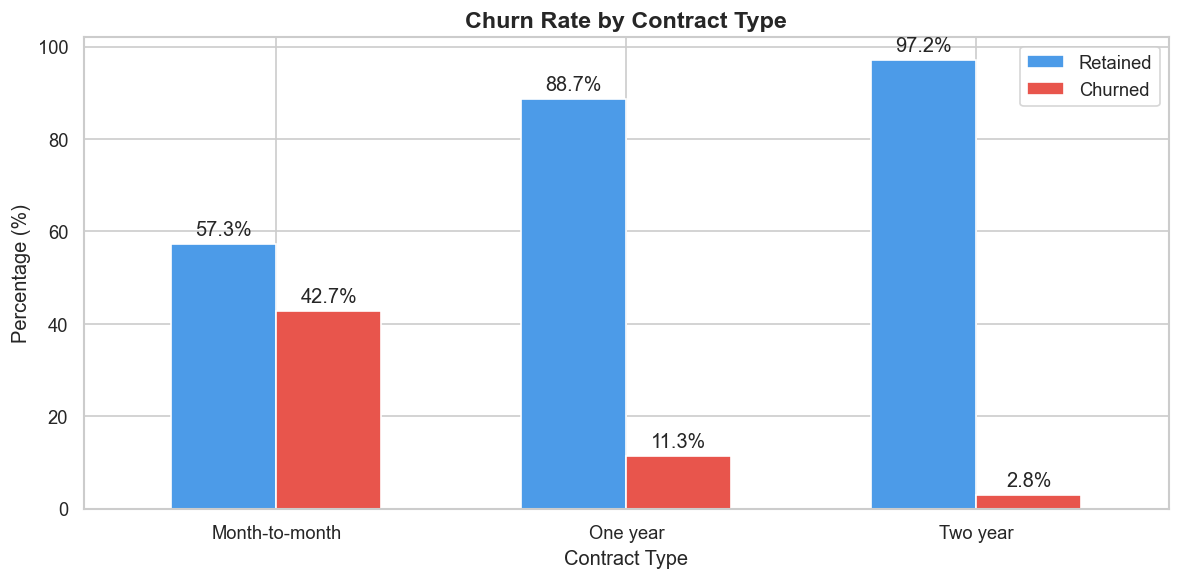

In [6]:
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100

ax = contract_churn.plot(kind='bar', figsize=(10, 5), color=['#4C9BE8', '#E8554C'],
                         edgecolor='white', width=0.6)
ax.set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Percentage (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['Retained', 'Churned'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.savefig('../images/eda_contract_churn.png', bbox_inches='tight')
plt.show()

## 4. Tenure Distribution — Do Newer Customers Churn More?

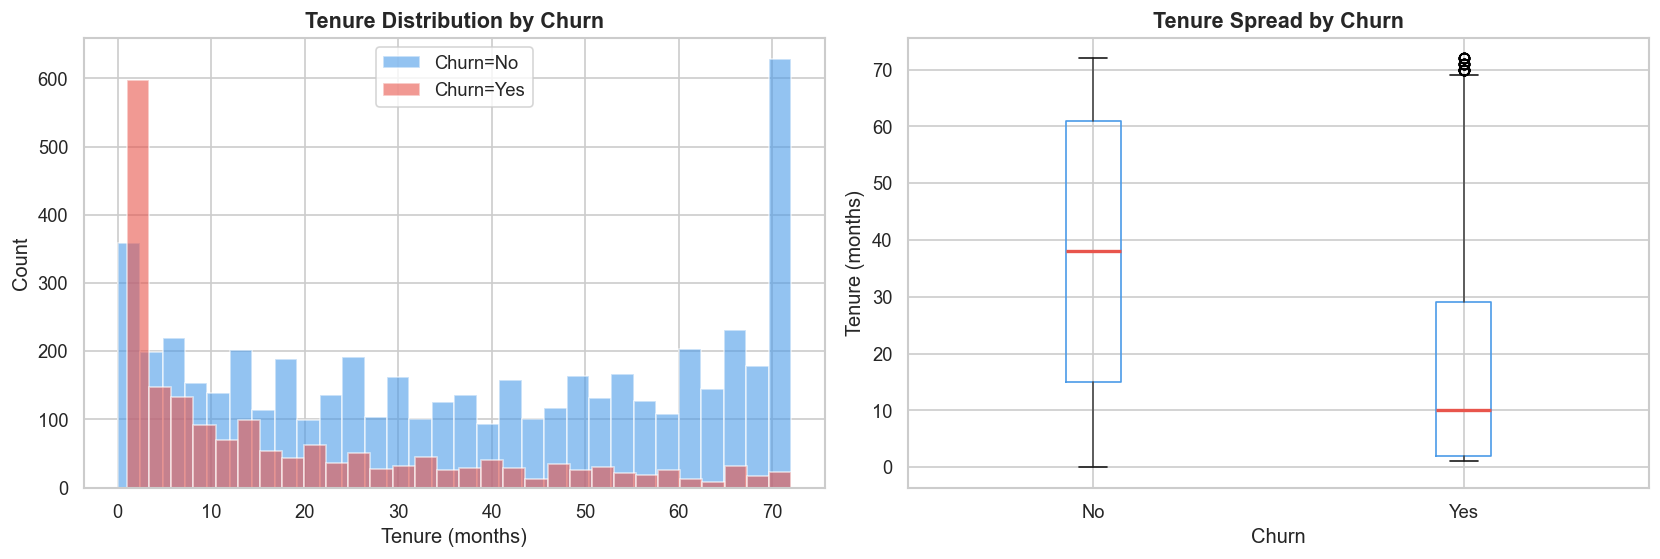

Average tenure - Retained: 37.6 months
Average tenure - Churned:  18.0 months


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram by churn
for label, color in [('No', '#4C9BE8'), ('Yes', '#E8554C')]:
    axes[0].hist(df[df['Churn'] == label]['tenure'], bins=30,
                 alpha=0.6, color=color, label=f'Churn={label}')
axes[0].set_title('Tenure Distribution by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Box plot
df.boxplot(column='tenure', by='Churn', ax=axes[1],
           boxprops=dict(color='#4C9BE8'),
           medianprops=dict(color='#E8554C', linewidth=2))
axes[1].set_title('Tenure Spread by Churn', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Churn')
axes[1].set_ylabel('Tenure (months)')
plt.suptitle('')

plt.tight_layout()
plt.savefig('../images/eda_tenure.png', bbox_inches='tight')
plt.show()

print('Average tenure - Retained:', df[df['Churn']=='No']['tenure'].mean().round(1), 'months')
print('Average tenure - Churned: ', df[df['Churn']=='Yes']['tenure'].mean().round(1), 'months')

## 5. Monthly Charges vs Churn

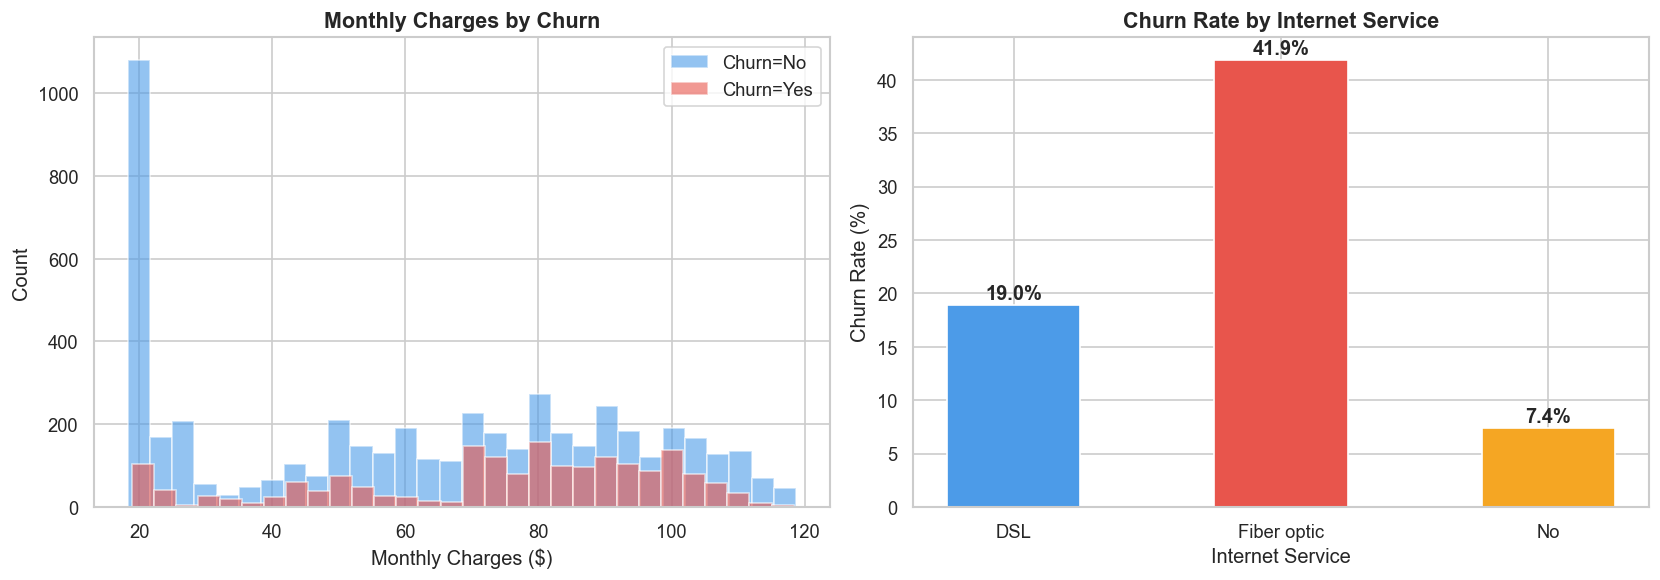

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Monthly charges distribution
for label, color in [('No', '#4C9BE8'), ('Yes', '#E8554C')]:
    axes[0].hist(df[df['Churn'] == label]['MonthlyCharges'], bins=30,
                 alpha=0.6, color=color, label=f'Churn={label}')
axes[0].set_title('Monthly Charges by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Monthly Charges ($)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Churn rate by internet service
internet_churn = df.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)
axes[1].bar(internet_churn.index, internet_churn.values,
            color=['#4C9BE8', '#E8554C', '#F5A623'], width=0.5)
axes[1].set_title('Churn Rate by Internet Service', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Internet Service')
axes[1].set_ylabel('Churn Rate (%)')
for i, v in enumerate(internet_churn.values):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../images/eda_charges_internet.png', bbox_inches='tight')
plt.show()

## 6. Key Insights from EDA

| Finding | Detail |
|---|---|
| Class imbalance | 73.5% retained vs 26.5% churned — must account for this in modelling |
| Contract type | Month-to-month customers churn at ~42%, vs ~11% for 1-year and ~3% for 2-year |
| Tenure | Churned customers average 18 months tenure vs 38 months for retained |
| Monthly charges | Higher charges correlate with higher churn |
| Internet service | Fiber optic customers churn at ~42% vs ~19% for DSL |

➡️ These insights will guide feature selection in the next notebook.